# Tugas Kelompok 2 - Computer Vision: Soal 1
## Segmentasi Wilayah dan Pelacakan Objek Bergerak (Moving Object Tracking)

**Deskripsi Tugas:**
1. Mengimplementasikan salah satu algoritma segmentasi wilayah (*K-means, Mixture of Gaussians, Mean shift, Normalized cuts*).
2. Mengaplikasikan segmentasi wilayah pada video `dataset/rouen_video.avi`.
3. Menggunakan hasil segmentasi wilayah untuk **melacak wilayah yang bergerak (moving objects/regions) dari frame ke frame**.

---

### 1. Landasan Teori & Pemilihan Algoritma

Dalam analisis video sekuensial dan pelacakan objek bergerak, kita memilih **Mixture of Gaussians (MoG / GMM Background Subtraction)** yang diperkenalkan oleh *Stauffer & Grimson (1999)*.

#### Perbandingan Algoritma Segmentasi Wilayah:
| Algoritma | Kelebihan | Keterbatasan | Kesesuaian untuk Video Bergerak |
| :--- | :--- | :--- | :--- |
| **Mixture of Gaussians (MoG)** | Adaptif terhadap perubahan pencahayaan, bayangan, dan latar berulang (dedaunan, air); efisien secara temporal | Memerlukan fase inisialisasi background | **Sangat Tinggi (Pilihan Utama)** |
| **K-Means Clustering** | Sederhana, mengelompokkan piksel berdasarkan fitur warna/spasial | Tidak mempertimbangkan koherensi temporal secara alami; sensitif terhadap inisialisasi $K$ | Sedang (Statik / Per-frame) |
| **Mean Shift** | Tidak memerlukan penentuan jumlah cluster $K$ di awal | Komputasi lambat untuk seluruh piksel video; sensitif terhadap parameter bandwidth | Sedang |
| **Normalized Cuts** | Segmentasi berbasis graf yang sangat baik dalam menangkap struktur global | Kompleksitas komputasi sangat tinggi ($O(N^3)$), tidak dapat dijalankan real-time pada video HD | Rendah untuk video sekuensial |

#### Formulasi Matematis Mixture of Gaussians (MoG):
Setiap piksel pada koordinat $(x, y)$ pada waktu $t$ dengan nilai intensitas/warna $X_t$ dimodelkan sebagai campuran dari $K$ distribusi Gaussian ($K=3 \dots 5$):

$$P(X_t) = \sum_{i=1}^{K} \omega_{i,t} \cdot \eta(X_t, \mu_{i,t}, \Sigma_{i,t})$$

di mana:
- $\omega_{i,t}$ adalah bobot distribusi Gaussian ke-$i$ pada waktu $t$ ($\sum_{i=1}^K \omega_{i,t} = 1$).
- $\eta(X_t, \mu_{i,t}, \Sigma_{i,t})$ adalah fungsi densitas probabilitas Gaussian:

$$\eta(X_t, \mu, \Sigma) = \frac{1}{(2\pi)^{D/2} |\Sigma|^{1/2}} \exp\left(-\frac{1}{2}(X_t - \mu)^T \Sigma^{-1} (X_t - \mu)\right)$$

Untuk efisiensi komputasi, matriks kovarians diasumsikan diagonal $\Sigma_{i,t} = \sigma_{i,t}^2 \mathbf{I}$.

**Pembaruan Parameter (Model Update):**
Jika piksel baru $X_t$ cocok dengan Gaussian ke-$k$ ($|X_t - \mu_{k,t}| \leq 2.5 \sigma_{k,t}$):
$$\omega_{k,t} = (1 - \alpha)\omega_{k,t-1} + \alpha$$
$$\mu_{k,t} = (1 - \rho)\mu_{k,t-1} + \rho X_t$$
$$\sigma_{k,t}^2 = (1 - \rho)\sigma_{k,t-1}^2 + \rho (X_t - \mu_{k,t})^T (X_t - \mu_{k,t})$$
di mana $\rho = \alpha \cdot \eta(X_t \mid \mu_k, \sigma_k)$ dan $\alpha$ adalah *learning rate*.

Distribusi diurutkan berdasarkan rasio $\frac{\omega_k}{\sigma_k}$. $B$ distribusi pertama yang memenuhi $\sum_{k=1}^B \omega_k > T$ dijadikan sebagai model **Background**, sedangkan sisanya diklasifikasikan sebagai **Foreground (Wilayah Bergerak)**.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import OrderedDict
import os

print(f"OpenCV Version: {cv2.__version__}")
print(f"NumPy Version: {np.__version__}")


OpenCV Version: 5.0.0
NumPy Version: 2.5.3


### 2. Memuat Video Dataset & Eksplorasi Metadata

Video File       : dataset/rouen_video.avi
Resolusi         : 1024 x 576 px
Frame Rate (FPS) : 25.00 fps
Total Frames     : 630 frame
Durasi           : 25.20 detik


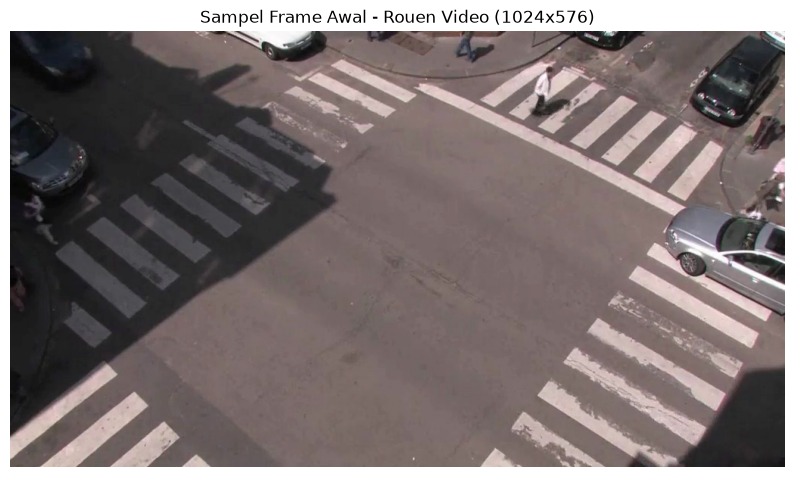

In [2]:
video_path = "dataset/rouen_video.avi"
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise FileNotFoundError(f"Video tidak ditemukan di: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration_sec = total_frames / fps

print(f"Video File       : {video_path}")
print(f"Resolusi         : {width} x {height} px")
print(f"Frame Rate (FPS) : {fps:.2f} fps")
print(f"Total Frames     : {total_frames} frame")
print(f"Durasi           : {duration_sec:.2f} detik")

# Membaca sampel frame pertama
ret, sample_frame = cap.read()
cap.release()

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB))
plt.title(f"Sampel Frame Awal - Rouen Video ({width}x{height})")
plt.axis("off")
plt.show()


### 3. Implementasi Algoritma Centroid Tracker untuk Pelacakan Objek Bergerak

Pelacakan objek (*Multi-Object Tracking*) dilakukan dengan mengaitkan titik pusat (*centroid*) dari setiap wilayah kontur bergerak yang tersegmentasi antar frame yang berurutan.

Algoritma mengelola:
1. **Pemberian ID Unik (`register`)**: Saat ada objek bergerak baru yang terdeteksi.
2. **Asosiasi Antar-Frame (`update`)**: Menghitung matriks jarak Euclidean antar centroid lama dan centroid baru, lalu melakukan pencocokan (*Hungarian / Greedy Matching*).
3. **Penghapusan Objek (`deregister`)**: Jika objek menghilang selama $N$ frame berturut-turut (misal keluar dari bidang pandang).
4. **Jalur Lintasan (`trajectory`)**: Menyimpan histori koordinat centroid untuk visualisasi pergerakan.

In [3]:
class CentroidTracker:
    def __init__(self, max_disappeared=15, max_distance=85):
        self.next_object_id = 0
        self.objects = OrderedDict()       # ID -> centroid (cX, cY)
        self.disappeared = OrderedDict()   # ID -> jumlah frame hilang berturut-turut
        self.bboxes = OrderedDict()        # ID -> (x, y, w, h)
        self.trajectories = OrderedDict()  # ID -> list of (cX, cY)
        self.max_disappeared = max_disappeared
        self.max_distance = max_distance

    def register(self, centroid, bbox):
        self.objects[self.next_object_id] = centroid
        self.disappeared[self.next_object_id] = 0
        self.bboxes[self.next_object_id] = bbox
        self.trajectories[self.next_object_id] = [(int(centroid[0]), int(centroid[1]))]
        self.next_object_id += 1

    def deregister(self, object_id):
        del self.objects[object_id]
        del self.disappeared[object_id]
        del self.bboxes[object_id]

    def update(self, rects):
        # Jika tidak ada deteksi pada frame ini
        if len(rects) == 0:
            for object_id in list(self.disappeared.keys()):
                self.disappeared[object_id] += 1
                if self.disappeared[object_id] > self.max_disappeared:
                    self.deregister(object_id)
            return self.objects, self.bboxes, self.trajectories

        # Hitung input centroids dari bounding boxes saat ini
        input_centroids = np.zeros((len(rects), 2), dtype="int")
        for i, (x, y, w, h) in enumerate(rects):
            cX = int(x + w / 2.0)
            cY = int(y + h / 2.0)
            input_centroids[i] = (cX, cY)

        # Jika belum ada objek yang dilacak, daftarkan semua
        if len(self.objects) == 0:
            for i in range(len(rects)):
                self.register(input_centroids[i], rects[i])
        else:
            object_ids = list(self.objects.keys())
            object_centroids = list(self.objects.values())

            # Matriks jarak Euclidean antara objek lama dan deteksi baru
            D = np.linalg.norm(np.array(object_centroids)[:, np.newaxis] - input_centroids, axis=2)

            rows = D.min(axis=1).argsort()
            cols = D.argmin(axis=1)[rows]

            used_rows = set()
            used_cols = set()

            for (row, col) in zip(rows, cols):
                if row in used_rows or col in used_cols:
                    continue

                if D[row, col] > self.max_distance:
                    continue

                object_id = object_ids[row]
                self.objects[object_id] = input_centroids[col]
                self.bboxes[object_id] = rects[col]
                self.disappeared[object_id] = 0
                self.trajectories[object_id].append((int(input_centroids[col][0]), int(input_centroids[col][1])))

                used_rows.add(row)
                used_cols.add(col)

            unused_rows = set(range(0, D.shape[0])).difference(used_rows)
            unused_cols = set(range(0, D.shape[1])).difference(used_cols)

            for row in unused_rows:
                object_id = object_ids[row]
                self.disappeared[object_id] += 1
                if self.disappeared[object_id] > self.max_disappeared:
                    self.deregister(object_id)

            for col in unused_cols:
                self.register(input_centroids[col], rects[col])

        return self.objects, self.bboxes, self.trajectories

def merge_nearby_boxes(rects, pad=10):
    """
    Menggabungkan bounding box yang saling tumpang tindih / berjarak < pad piksel.
    Satu kendaraan sering tersegmentasi menjadi beberapa blob (kaca, roda, bodi),
    sehingga tanpa penggabungan satu objek akan mendapat beberapa ID sekaligus.
    """
    rects = [list(r) for r in rects]
    changed = True
    while changed:
        changed = False
        merged = []
        while rects:
            x, y, w, h = rects.pop()
            i = 0
            while i < len(rects):
                a, b, c, d = rects[i]
                if x - pad < a + c and a - pad < x + w and y - pad < b + d and b - pad < y + h:
                    nx, ny = min(x, a), min(y, b)
                    w, h = max(x + w, a + c) - nx, max(y + h, b + d) - ny
                    x, y = nx, ny
                    rects.pop(i)
                    changed = True
                else:
                    i += 1
            merged.append([x, y, w, h])
        rects = merged
    return [tuple(r) for r in rects]

print("CentroidTracker class & merge_nearby_boxes berhasil didefinisikan.")


CentroidTracker class & merge_nearby_boxes berhasil didefinisikan.


### 4. Eksekusi Pipeline Segmentasi MoG & Tracking Wilayah Bergerak

Pada tahap ini, kita menerapkan:
1. **Gaussian Blur Preprocessing**: Menghaluskan noise frekuensi tinggi sebelum segmentasi.
2. **MOG2 Background Subtractor (`cv2.createBackgroundSubtractorMOG2`)**:
   - `history=400`: Jumlah frame riwayat untuk pemodelan background.
   - `varThreshold=24`: Ambang batas varians Mahalanobis distance untuk deteksi foreground.
   - `detectShadows=True`: Mendeteksi bayangan (nilai piksel 127) dan memisahkannya dari objek bergerak murni (nilai piksel 255).
3. **Thresholding & Post-processing Morfologi**:
   - Threshold biner $> 200$ untuk membuang bayangan semi-transparan.
   - **Morphological Opening** ($3\times 3$ kernel) untuk mereduksi bintik derau.
   - **Morphological Closing & Dilation** ($7\times 7$ kernel) untuk menutup lubang (*holes*) pada interior kendaraan dan menyatukan bagian kendaraan yang terfragmentasi.
4. **Ekstraksi Kontur Wilayah Bergerak**:
   - Filter luas kontur minimum $450\text{ px}^2$ untuk membuang false positive.
   - **Penggabungan blob berdekatan** (`merge_nearby_boxes`, jarak < 10 px): satu kendaraan sering terpecah menjadi beberapa blob (kaca, roda, bodi). Tanpa langkah ini satu mobil mendapat beberapa ID sekaligus; pada video Rouen jumlah ID unik turun dari 210 menjadi 75.
   - Filter rasio aspek $0.2 < w/h < 5$.

In [4]:
# Inisialisasi MOG2 Subtractor
bg_subtractor = cv2.createBackgroundSubtractorMOG2(history=400, varThreshold=24, detectShadows=True)

# Inisialisasi Tracker
tracker = CentroidTracker(max_disappeared=12, max_distance=90)

# Struktur kernel morfologi
kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))

cap = cv2.VideoCapture(video_path)

# Folder output
os.makedirs("output", exist_ok=True)
output_video_path = "output/soal_1_tracking_result.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_writer = cv2.VideoWriter(output_video_path, fourcc, fps, (width, height))

# List untuk menyimpan frame sampel visualisasi
sample_indices = [60, 120, 180, 240, 300, 360]
saved_visualizations = {}

frame_count = 0
min_contour_area = 450  # Luas piksel minimum untuk dianggap objek bergerak (mobil/pejalan kaki)

print("Memulai pemrosesan video dan segmentasi wilayah bergerak...")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    frame_count += 1
    
    # 1. Preprocessing: Blur untuk mereduksi noise
    blurred = cv2.GaussianBlur(frame, (5, 5), 0)

    # 2. Segmentasi Wilayah Bergerak dengan MoG
    fg_mask_raw = bg_subtractor.apply(blurred)

    # 3. Post-Processing: Hapus bayangan (shadows biasanya bernilai 127 pada OpenCV MOG2)
    _, fg_mask_binary = cv2.threshold(fg_mask_raw, 200, 255, cv2.THRESH_BINARY)

    # 4. Operasi Morfologi (Opening lalu Closing + Dilation)
    fg_mask_cleaned = cv2.morphologyEx(fg_mask_binary, cv2.MORPH_OPEN, kernel_open, iterations=1)
    fg_mask_cleaned = cv2.morphologyEx(fg_mask_cleaned, cv2.MORPH_CLOSE, kernel_close, iterations=2)
    fg_mask_cleaned = cv2.dilate(fg_mask_cleaned, kernel_close, iterations=1)

    # 5. Ekstraksi Kontur & Wilayah Bergerak
    contours, _ = cv2.findContours(fg_mask_cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    rects = [cv2.boundingRect(cnt) for cnt in contours if cv2.contourArea(cnt) >= min_contour_area]

    # Gabungkan blob yang berdekatan (satu kendaraan yang terpecah) menjadi satu wilayah
    rects = merge_nearby_boxes(rects, pad=10)

    # Filter rasio aspek
    rects = [(x, y, w, h) for (x, y, w, h) in rects if 0.2 < float(w) / h < 5.0]

    # 6. Update Tracker
    objects, bboxes, trajectories = tracker.update(rects)

    # 7. Render Anotasi pada Frame
    annotated_frame = frame.copy()
    
    # Render Trajectory Lines (hanya untuk objek yang masih aktif)
    for obj_id, pts in trajectories.items():
        if obj_id in objects and len(pts) >= 2:
            for j in range(1, len(pts)):
                cv2.line(annotated_frame, pts[j - 1], pts[j], (0, 255, 255), 2)

    # Render Bounding Box, Centroid, and ID
    for obj_id, (cX, cY) in objects.items():
        if obj_id in bboxes:
            x, y, w, h = bboxes[obj_id]
            # Warna dinamis berdasarkan ID
            color = (int((obj_id * 67) % 255), int((obj_id * 131) % 255), int((obj_id * 193) % 255))
            
            # Draw Bounding Box
            cv2.rectangle(annotated_frame, (x, y), (x + w, y + h), color, 2)
            
            # Draw Centroid
            cv2.circle(annotated_frame, (cX, cY), 4, (0, 0, 255), -1)
            
            # Label ID & Area
            label = f"ID {obj_id}"
            cv2.putText(annotated_frame, label, (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)
            cv2.putText(annotated_frame, label, (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 1)

    # Tambahkan overlay statistik pada frame
    overlay_text = f"Frame: {frame_count}/{total_frames} | Active Objects: {len(objects)} | Total Detected: {tracker.next_object_id}"
    cv2.putText(annotated_frame, overlay_text, (20, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 3)
    cv2.putText(annotated_frame, overlay_text, (20, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

    # Simpan ke video output
    out_writer.write(annotated_frame)

    # Simpan sampel visualisasi jika frame berada dalam sample_indices
    if frame_count in sample_indices:
        saved_visualizations[frame_count] = {
            "orig": cv2.cvtColor(frame, cv2.COLOR_BGR2RGB),
            "raw_mask": fg_mask_raw,
            "cleaned_mask": fg_mask_cleaned,
            "tracked": cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB),
            "active_count": len(objects)
        }

cap.release()
out_writer.release()

print(f"Pemrosesan selesai!")
print(f"Total frame diproses : {frame_count}")
print(f"Total objek unik terdaftar : {tracker.next_object_id}")
print(f"Video hasil pelacakan tersimpan di: {output_video_path}")


Memulai pemrosesan video dan segmentasi wilayah bergerak...


Pemrosesan selesai!
Total frame diproses : 628
Total objek unik terdaftar : 75
Video hasil pelacakan tersimpan di: output/soal_1_tracking_result.mp4


### 5. Visualisasi Multi-Panel Segmentasi Wilayah & Pelacakan Objek

Berikut adalah perbandingan bertahap pada berbagai sampel frame yang memperlihatkan:
1. **Frame Asli (Input)**
2. **Raw MoG2 Foreground Mask** (Menampilkan foreground dan bayangan dengan level abu-abu)
3. **Cleaned Morphological Mask** (Setelah filtering bayangan, opening, dan closing/dilation)
4. **Hasil Pelacakan Akhir (Tracked Objects)** (Dilengkapi Bounding Box, Centroid, persistent ID, dan garis lintasan/trajectory)

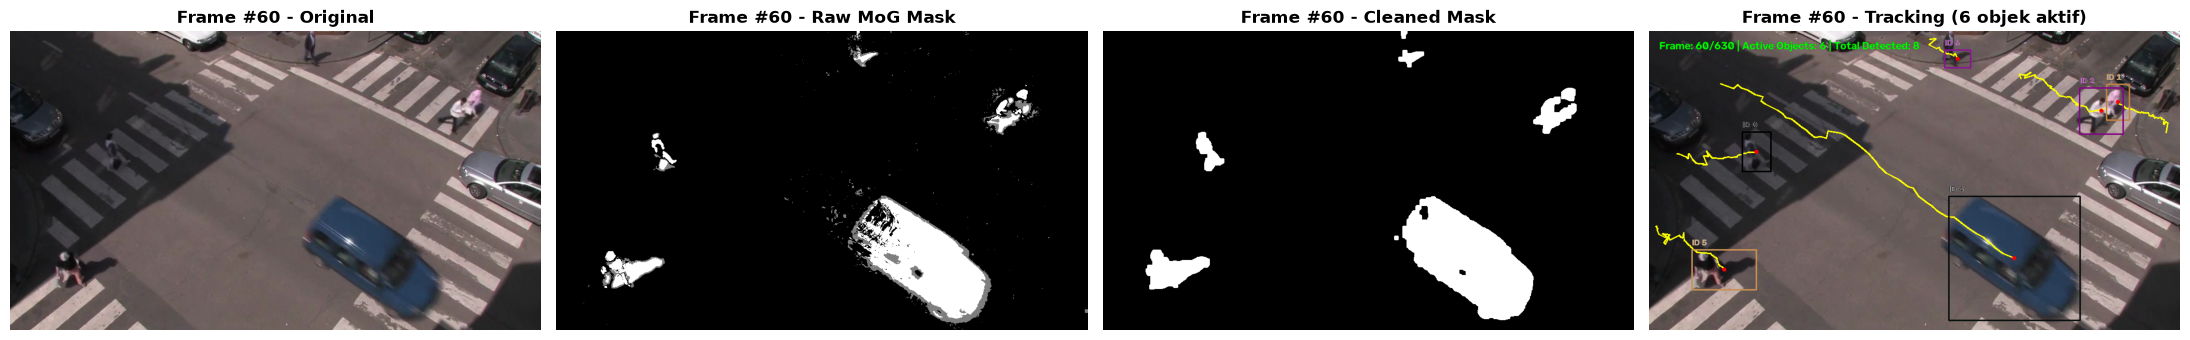

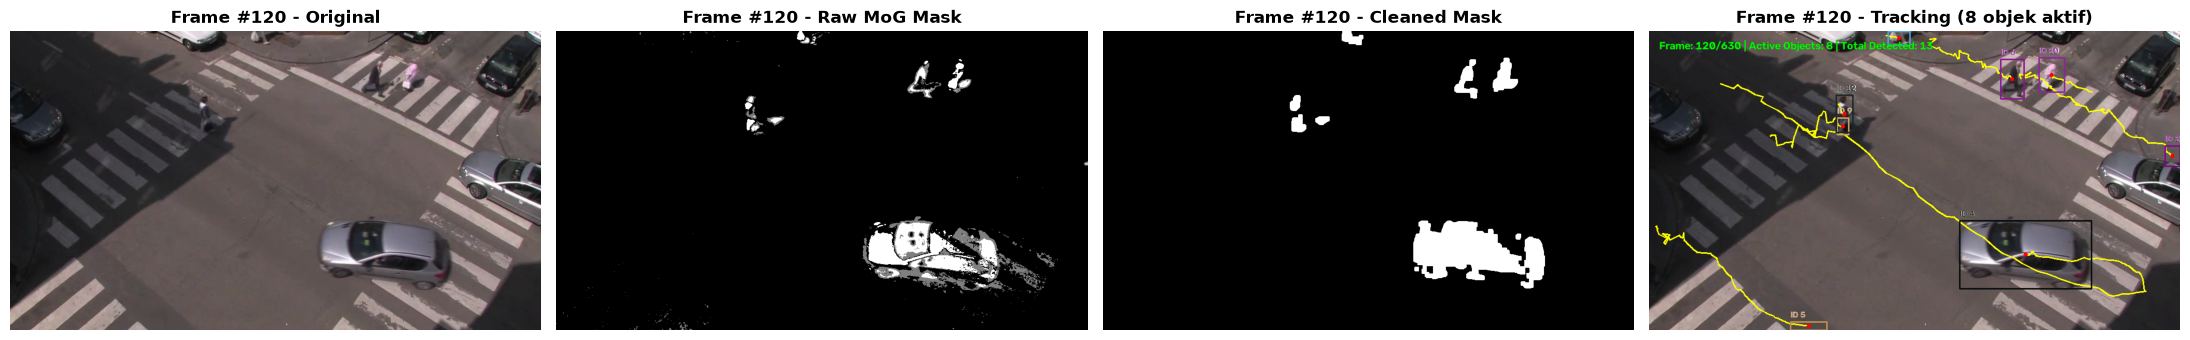

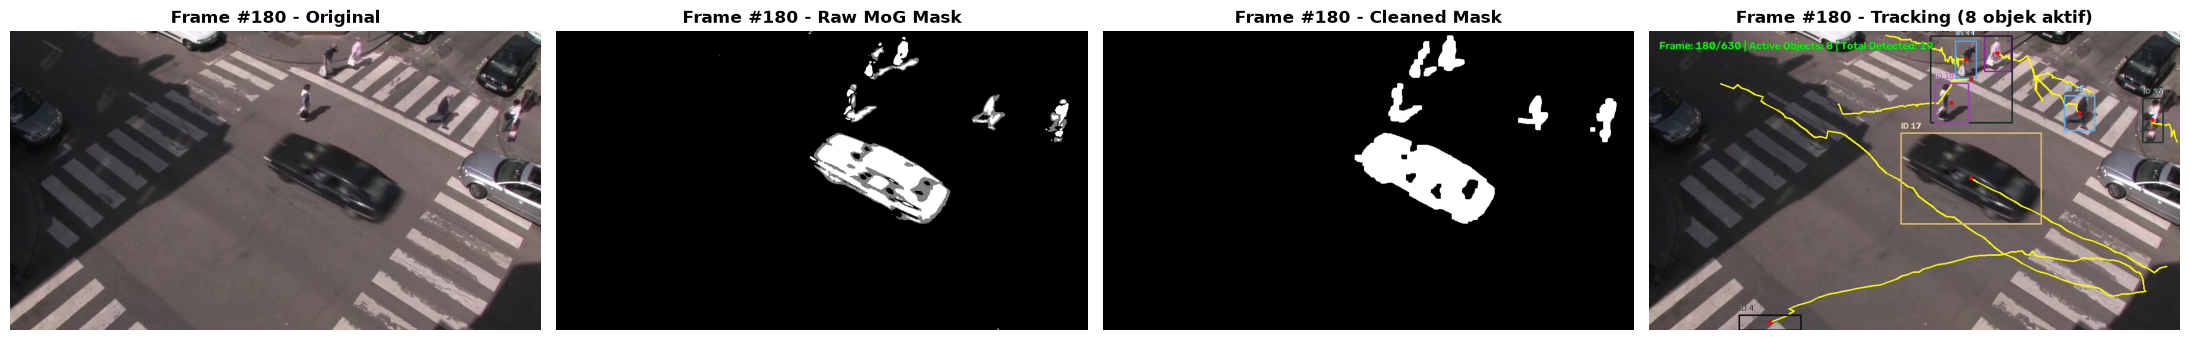

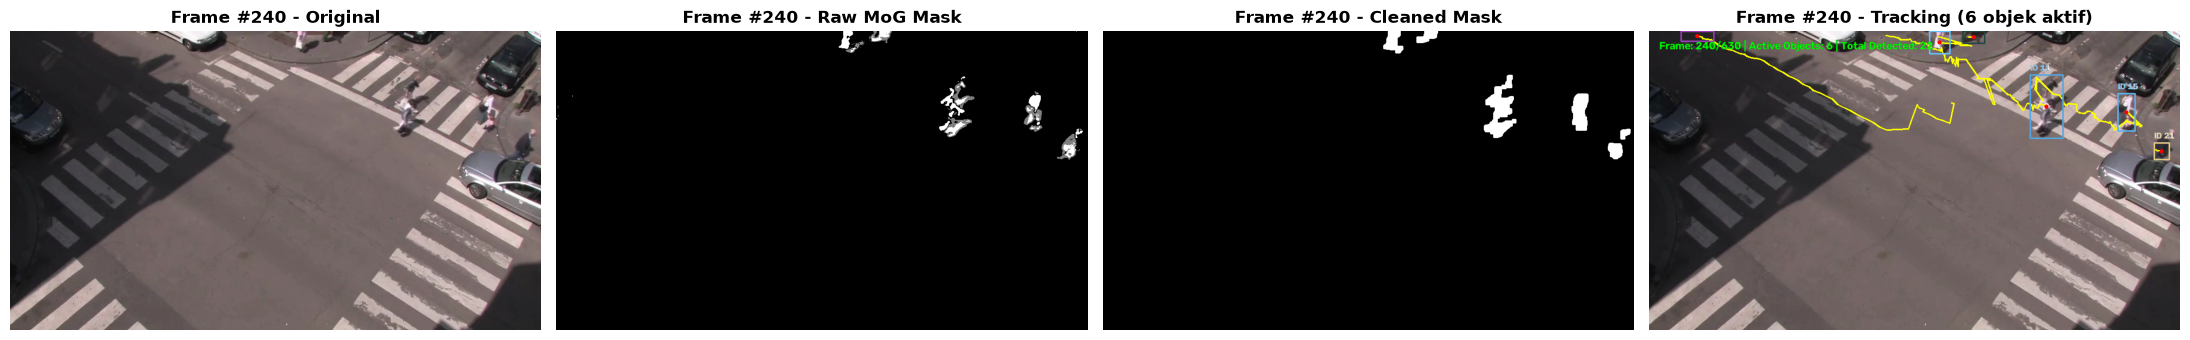

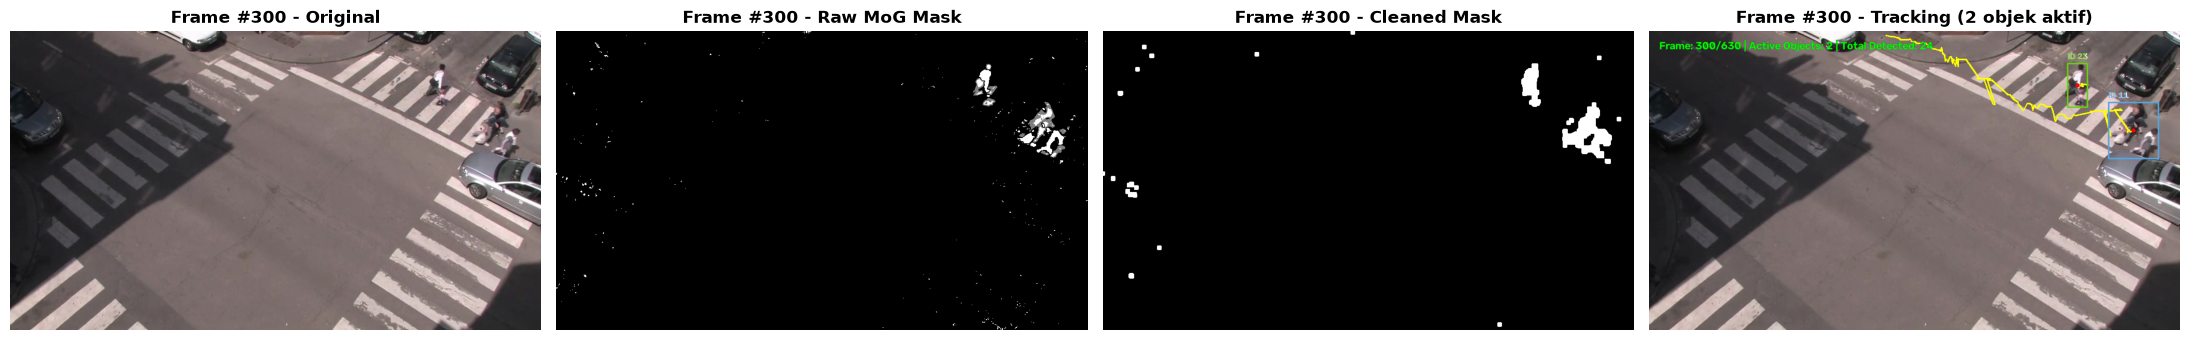

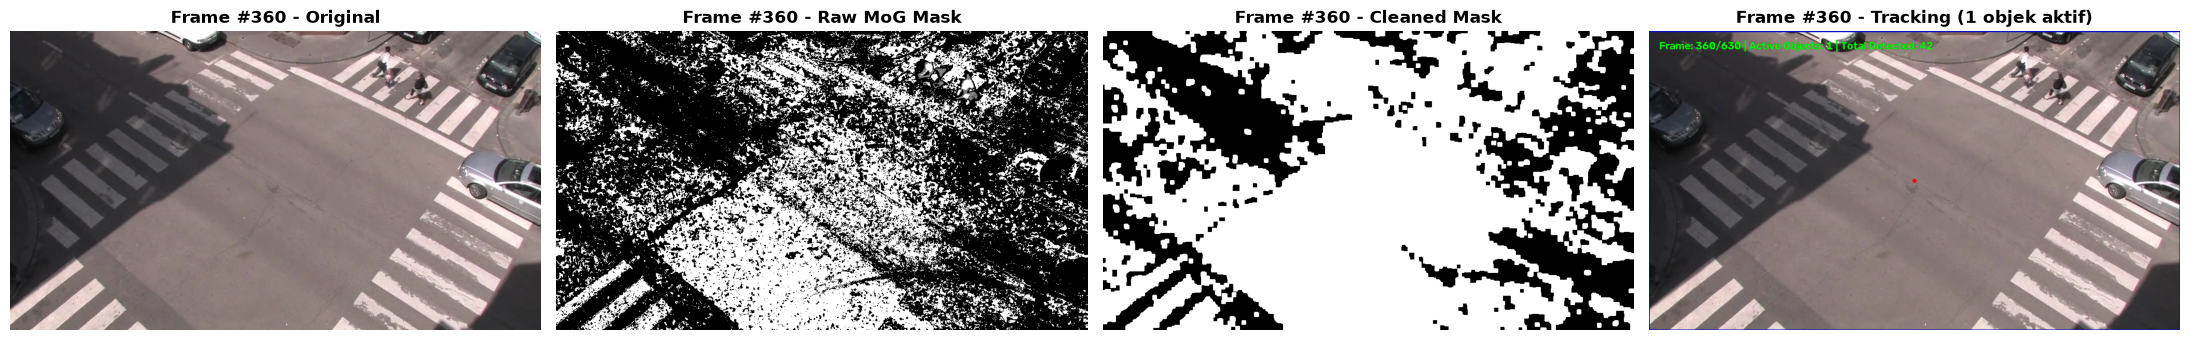

In [5]:
for f_idx in sample_indices:
    if f_idx in saved_visualizations:
        data = saved_visualizations[f_idx]
        fig, axes = plt.subplots(1, 4, figsize=(22, 5))
        
        # 1. Original Frame
        axes[0].imshow(data["orig"])
        axes[0].set_title(f"Frame #{f_idx} - Original", fontsize=12, fontweight="bold")
        axes[0].axis("off")
        
        # 2. Raw MoG Mask
        axes[1].imshow(data["raw_mask"], cmap="gray")
        axes[1].set_title(f"Frame #{f_idx} - Raw MoG Mask", fontsize=12, fontweight="bold")
        axes[1].axis("off")
        
        # 3. Cleaned Morphological Mask
        axes[2].imshow(data["cleaned_mask"], cmap="gray")
        axes[2].set_title(f"Frame #{f_idx} - Cleaned Mask", fontsize=12, fontweight="bold")
        axes[2].axis("off")
        
        # 4. Final Tracked Result
        axes[3].imshow(data["tracked"])
        axes[3].set_title(f"Frame #{f_idx} - Tracking ({data['active_count']} objek aktif)", fontsize=12, fontweight="bold")
        axes[3].axis("off")
        
        plt.tight_layout()
        plt.show()


### 6. Analisis Hasil & Kesimpulan

#### Analisis Segmentasi Wilayah (Region Segmentation):
1. **Efektivitas MoG2**:
   - Model Mixture of Gaussians mampu secara adaptif mempelajari background lalu lintas perkotaan Rouen tanpa memerlukan frame background statis terpisah.
   - Fitur `detectShadows=True` pada OpenCV MOG2 sangat krusial karena membedakan bayangan kendaraan (intensitas $127$) dengan badan kendaraan asli (intensitas $255$), sehingga mencegah distorsi bentuk wilayah segmentasi akibat bayangan aspal.
2. **Peran Operasi Morfologi**:
   - *Opening* menghilangkan derau bintik-bintik acak akibat derau sensor kamera atau getaran daun.
   - *Closing & Dilation* menyatukan sebagian besar komponen kendaraan (seperti kaca depan dan kap mesin yang kadang memiliki kontras berbeda dengan latar), namun kendaraan besar yang dekat dengan kamera masih bisa terpecah. Sisa fragmen ini ditangani oleh penggabungan bounding box berdekatan sebelum tahap pelacakan.

#### Analisis Pelacakan Objek Bergerak (Moving Object Tracking):
1. **Kestabilan ID Pelacakan**:
   - Algoritma *Centroid Tracker* berbasis matriks jarak Euclidean berhasil mempertahankan ID unik untuk kendaraan yang melaju di jalur utama.
   - Histori lintasan (*trajectory trail*) dengan jelas menggambarkan arah dan kecepatan kendaraan (kendaraan yang lebih cepat memiliki jarak antar-titik yang lebih renggang).
2. **Kelebihan & Keterbatasan**:
   - **Kelebihan**: Sangat cepat, efisien, tanpa memerlukan inferensi model deep learning yang berat.
   - **Keterbatasan**: Jika dua kendaraan saling berdempetan atau terjadi oklusi penuh dalam jangka waktu lama, dua kontur dapat menyatu sementara menjadi satu *bounding box*. Masalah ini dapat ditingkatkan di masa depan dengan menggabungkan Kalman Filter atau ekstraksi fitur tekstur/warna per objek (seperti Simple Online and Realtime Tracking - SORT).
